# S-G2-M time distributions
Using original parameter set

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rc, rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
from scipy.stats import exponnorm, norm
import pandas as pd
import math
from pathlib import Path
import re
import sys

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)
    
IMT_DATADIR = Path("../../Data/Exp_Intermitotic_Times")

rcParams.update({'figure.autolayout': True})

# add path to fit functions
sys.path.insert(0, "./../../Python")
from fits import emg_fit_func, fit_EMGMM


In [3]:
file_location = os.path.join(IMT_DATADIR,'*imt_*.csv')
filenames = glob.glob(file_location)
filenames.sort()
filenames

['..\\..\\Data\\Exp_Intermitotic_Times\\02kpa_dmso_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\02kpa_erl_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\06kpa_dmso_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\06kpa_erl_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\4kpa_dmso_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\4kpa_erl_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\55kpa_dmso_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\55kpa_erl_imt_181017.csv']

In [5]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)  # histogram bin centers 

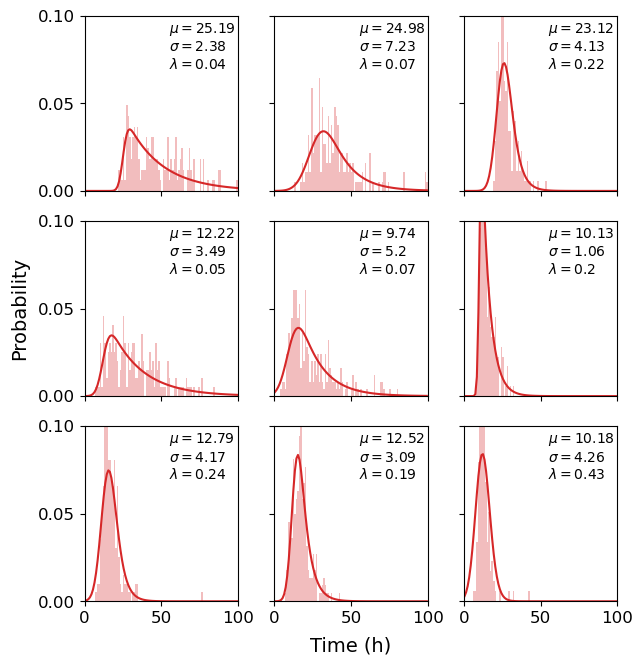

In [59]:
win = 21
pol = 2
size = (7,7)
c1 = "tab:blue"
c2 = "tab:red"
xmin = 0
xmax = 100
ymin = 0
ymax = 0.1

fig, axes = plt.subplots(3, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

data = np.array(IMTs[1]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0,0].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0,0].plot(centers, fitted_curve, color=c2)
axes[0,0].set_xlim([xmin, xmax])
axes[0,0].set_ylim([ymin, ymax])
axes[0,0].set_yticks([0, 0.05, 0.1])
axes[0,0].axes.xaxis.set_ticklabels([])
axes[0,0].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

data = np.array(IMTs[5]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0,1].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0,1].plot(centers, fitted_curve, color=c2)
axes[0,1].set_xlim([xmin, xmax])
axes[0,1].set_ylim([ymin, ymax])
axes[0,1].set_yticks([0, 0.05, 0.1])
axes[0,1].axes.xaxis.set_ticklabels([])
axes[0,1].axes.yaxis.set_ticklabels([])
axes[0,1].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

data = np.array(IMTs[7]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0,2].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0,2].plot(centers, fitted_curve, color=c2)
axes[0,2].set_xlim([xmin, xmax])
axes[0,2].set_ylim([ymin, ymax])
axes[0,2].set_yticks([0, 0.05, 0.1])
axes[0,2].axes.xaxis.set_ticklabels([])
axes[0,2].axes.yaxis.set_ticklabels([])
axes[0,2].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

cond=pd.Series(data={'stiff':0.2, 'drug':'ERL'})
G1 = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['G1_t']
G1 = G1[~np.isnan(G1)]
data = G1[~np.isnan(G1)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1,0].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1,0].plot(centers, fitted_curve, color=c2)
axes[1,0].set_xlim([xmin, xmax])
axes[1,0].set_ylim([ymin, ymax])
axes[1,0].set_yticks([0, 0.05, 0.1])
axes[1,0].axes.xaxis.set_ticklabels([])
axes[1,0].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

cond=pd.Series(data={'stiff':4, 'drug':'ERL'})
G1 = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['G1_t']
G1 = G1[~np.isnan(G1)]
data = G1[~np.isnan(G1)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1,1].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1,1].plot(centers, fitted_curve, color=c2)
axes[1,1].set_xlim([xmin, xmax])
axes[1,1].set_ylim([ymin, ymax])
axes[1,1].set_yticks([0, 0.05, 0.1])
axes[1,1].axes.xaxis.set_ticklabels([])
axes[1,1].axes.yaxis.set_ticklabels([])
axes[1,1].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

cond=pd.Series(data={'stiff':55, 'drug':'ERL'})
G1 = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['G1_t']
G1 = G1[~np.isnan(G1)]
data = G1[~np.isnan(G1)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1,2].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1,2].plot(centers, fitted_curve, color=c2)
axes[1,2].set_xlim([xmin, xmax])
axes[1,2].set_ylim([ymin, ymax])
axes[1,2].set_yticks([0, 0.05, 0.1])
axes[1,2].axes.xaxis.set_ticklabels([])
axes[1,2].axes.yaxis.set_ticklabels([])
axes[1,2].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

cond=pd.Series(data={'stiff':0.2, 'drug':'ERL'})
SM = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['S-M_t']
SM = SM[~np.isnan(SM)]
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2,0].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2,0].plot(centers, fitted_curve, color=c2)
axes[2,0].set_xlim([xmin, xmax])
axes[2,0].set_ylim([ymin, ymax])
axes[2,0].set_yticks([0, 0.05, 0.1])
axes[2,0].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

cond=pd.Series(data={'stiff':4, 'drug':'ERL'})
SM = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['S-M_t']
SM = SM[~np.isnan(SM)]
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2,1].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2,1].plot(centers, fitted_curve, color=c2)
axes[2,1].set_xlim([xmin, xmax])
axes[2,1].set_ylim([ymin, ymax])
axes[2,1].set_yticks([0, 0.05, 0.1])
axes[2,1].axes.yaxis.set_ticklabels([])
axes[2,1].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

cond=pd.Series(data={'stiff':55, 'drug':'ERL'})
SM = all_IMTs[(all_IMTs['Stiffness']==cond['stiff']) & (all_IMTs['Drug']==cond['drug'])]['S-M_t']
SM = SM[~np.isnan(SM)]
data = SM[~np.isnan(SM)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2,2].stairs(h, edges, orientation="vertical", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2,2].plot(centers, fitted_curve, color=c2)
axes[2,2].set_xlim([xmin, xmax])
axes[2,2].set_ylim([ymin, ymax])
axes[2,2].set_yticks([0, 0.05, 0.1])
axes[2,2].axes.yaxis.set_ticklabels([])
axes[2,2].text(55, 0.07, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Time (h)', labelpad=25)
ax.set_ylabel('Probability', labelpad=40)

fig1s = Path(SAVEDIR, 'fig1supp.svg')

if SAVEFILES and (OVERWRITE or not fig1s.exists()):
    plt.savefig(fig1s, bbox_inches='tight')
else:
    plt.figure()
